# How `L08-solution.ipynb` works: a guided tour with examples

This notebook explains the code of the lab step by step. Every example runs **the same functions** as `L08-solution.ipynb`, loaded directly from that notebook, so what you see here is exactly what the solution does.

**The idea in one sentence:** the projector draws a dark–light edge, which in space is a *plane of light*; every camera pixel on the edge is a *ray*; where the ray meets the plane is a 3D point.

| Part | What you will see |
|---|---|
| 1 | The pinhole model: projecting a point and turning a pixel back into a ray |
| 2 | The edge patterns sent to the projector |
| 3 | `detect_edge`, step by step, and why it divides by white − black |
| 4 | A plane of light and its intersection with a camera ray |
| 5 | A complete mini-scan of a synthetic object with a known shape, compared with the truth |
| 6 | The pre-lab depth-error formula, tested with noise |
| 7 | `fit_plane` and the residual map |
| 8 | Your real data: one scan photo from pixels to 3D points |
| 9 | Your real data: how the calibration finds the checkerboard and the projected dots |

Run the cells from top to bottom. Parts 1–7 need no data; parts 8–9 use the photos and the calibration in `setup-act`.

In [1]:
%matplotlib inline
import itertools, json, math, os
from glob import glob

import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

np.set_printoptions(suppress=True, precision=3)

def to_gray(image):
    return image @ np.array([0.2126, 0.7152, 0.0722]) if image.ndim == 3 else image

# Load the functions of the solution notebook, so the examples use exactly the same code
SOLUTION = {c.get('id'): ''.join(c['source']) for c in json.load(open('L08-solution.ipynb', encoding='utf8'))['cells']}

def use_solution_code(cell_id, stop_at=None):
    """Runs one code cell of L08-solution.ipynb here (only its beginning if stop_at is given)"""
    source = SOLUTION[cell_id]
    exec(source[:source.index(stop_at)] if stop_at else source, globals())

for cell_id in ['l08-011',   # load_projector_panel_points
                'l08-021',   # generate_slset
                'l08-029',   # detect_edge
                'l08-031',   # pixel_to_ray
                'l08-032',   # intersect
                'l08-033',   # reconstruct, remove_outliers, show_cloud
                'l08-051']:  # fit_plane
    use_solution_code(cell_id)
print('loaded from L08-solution.ipynb:', [f for f in ['generate_slset', 'detect_edge', 'pixel_to_ray', 'intersect',
                                                      'reconstruct', 'remove_outliers', 'show_cloud', 'fit_plane'] if f in globals()])

loaded from L08-solution.ipynb: ['generate_slset', 'detect_edge', 'pixel_to_ray', 'intersect', 'reconstruct', 'remove_outliers', 'show_cloud', 'fit_plane']


## 1. The pinhole model: from a 3D point to a pixel, and back

A camera (or a projector) maps a world point $\mathbf X$ to a pixel $\tilde{\mathbf x} \sim K(R\mathbf X + \mathbf t)$:

- $K$ (intrinsic matrix): focal length $f$ in pixels and the image centre $(c_x, c_y)$;
- $R, \mathbf t$ (extrinsics): rotation and translation from world to camera coordinates.

The pre-lab showed the way back: all points seen at pixel $\tilde{\mathbf x}$ lie on the **ray** $\mathbf X(\lambda) = \mathbf C + \lambda\,\mathbf d$ with $\mathbf C = -R^\top\mathbf t$ and $\mathbf d = R^\top K^{-1}\tilde{\mathbf x}$. This is what `pixel_to_ray` computes.

**Example:** a camera 500 mm in front of the world origin looks at the point (30, −20, 40) mm.

In [2]:
K = np.array([[800.0, 0, 320], [0, 800.0, 240], [0, 0, 1]])   # f = 800 px, image 640 x 480
R = np.eye(3)                                                   # camera axes = world axes
t = np.array([0.0, 0.0, 500.0])                                 # world origin is 500 mm in front of the camera
X = np.array([30.0, -20.0, 40.0])                               # a world point in mm

x = K @ (R @ X + t)                 # homogeneous pixel
pixel = x[:2] / x[2]                # divide by the third coordinate
print('the point', X, 'is seen at pixel', pixel)

# back from the pixel to a ray (the solution's function); no lens distortion in this example
C, d = pixel_to_ray(K, np.zeros(5), R, t, pixel[None, :])
print('camera centre C =', C, '  ray direction d =', d[0])

# the point must lie on the ray: find lambda with C + lambda * d = X
lam = (X - C)[2] / d[0, 2]
print('C + lambda d =', C + lam * d[0], 'for lambda =', round(lam, 2), '(= depth of the point in front of the camera)')

the point [ 30. -20.  40.] is seen at pixel [364.444 210.37 ]
camera centre C = [   0.    0. -500.]   ray direction d = [ 0.056 -0.037  1.   ]
C + lambda d = [ 30. -20.  40.] for lambda = 540.0 (= depth of the point in front of the camera)


**What to notice:** the ray goes back exactly through the original point. The third coordinate of $K^{-1}\tilde{\mathbf x}$ is 1, so $\lambda$ is the distance of the point *along the camera axis* (540 mm here: 500 + 40).

## 2. The edge patterns: `generate_slset`

Each pattern is black on the left and white on the right of one column. The edge is the border between two pixels, so for "white from column 600 on" the edge lies at $x = 599.5$. The function stores the two ends of each edge: top $(x, -0.5)$ and bottom $(x, 799.5)$. Those two panel points later define the plane of light.

**Example:** 5 patterns between columns 300 and 900, saved to a temporary folder.

upper ends (x, y):
 [[299.5  -0.5]
 [449.5  -0.5]
 [599.5  -0.5]
 [749.5  -0.5]
 [899.5  -0.5]]
lower ends (x, y):
 [[299.5 799.5]
 [449.5 799.5]
 [599.5 799.5]
 [749.5 799.5]
 [899.5 799.5]]


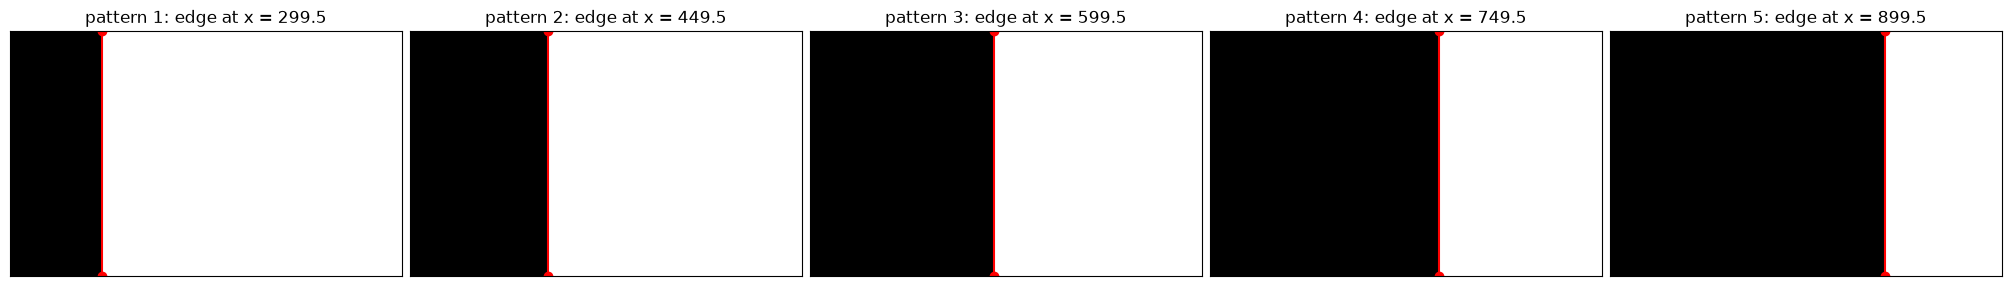

In [3]:
demo_points = generate_slset(5, path='_demo_patterns/structured-light-patterns', x_range=(300, 900))
print('upper ends (x, y):\n', demo_points[0])
print('lower ends (x, y):\n', demo_points[1])

fig, axes = plt.subplots(1, 5, figsize=(20, 3), constrained_layout=True)
for k, ax in enumerate(axes):
    ax.imshow(cv.imread(f'_demo_patterns/structured-light-patterns/pattern-{k + 1:02d}.png', 0), cmap='gray', vmin=0, vmax=255)
    ax.plot(demo_points[:, k, 0], demo_points[:, k, 1], 'ro-', ms=6)
    ax.set_title(f'pattern {k + 1}: edge at x = {demo_points[0, k, 0]}')
    ax.set_xticks([]); ax.set_yticks([])
plt.show()

## 3. Finding the edge in a photo: `detect_edge`

In a photo the edge is not a perfect step: it is blurred, and the surface has dark and bright parts (texture, printed squares, shadows). `detect_edge` solves this in five steps:

1. **Normalize** every pixel: $v = \dfrac{\text{photo} - \text{black}}{\text{white} - \text{black}}$. Then $v = 0$ where the pixel is dark, $v = 1$ where it is lit, and **$v = 0.5$ exactly on the edge**, whatever the surface colour.
2. **Ignore** pixels where white − black is small (shadow, background).
3. In every row, find places where $v$ goes from below 0.5 to above 0.5 (dark on the left, light on the right).
4. Keep the **strongest** crossing (mean of 20 pixels on the right minus mean of 20 pixels on the left > 0.4).
5. **Interpolate** between the two pixels around the crossing to get a sub-pixel position.

**Example:** a synthetic row of a striped surface with the true edge at $x = 50.3$.

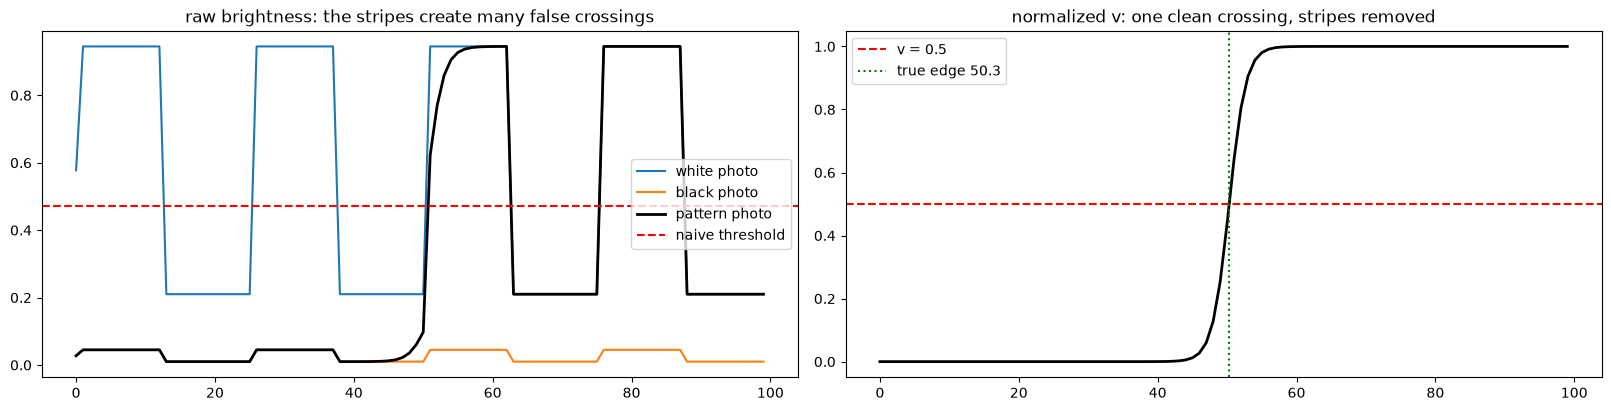

detect_edge finds x = 50.305 in each of 30 rows (true 50.300)
a naive threshold on the raw brightness crosses at x = [50 75] -> more than one crossing, and only one is the edge


In [4]:
xs = np.arange(100, dtype=float)
albedo = 0.55 + 0.35 * np.sign(np.sin(xs / 4))                        # striped surface: 0.2 or 0.9
light = 1 / (1 + np.exp(-(xs - 50.3) / 1.2))                           # blurred edge, true position 50.3
ambient = 0.05
white_row = albedo * (ambient + 1.0)
black_row = albedo * ambient
photo_row = albedo * (ambient + light)
v = (photo_row - black_row) / (white_row - black_row)

fig, axes = plt.subplots(1, 2, figsize=(16, 4), constrained_layout=True)
axes[0].plot(xs, white_row, label='white photo'); axes[0].plot(xs, black_row, label='black photo')
axes[0].plot(xs, photo_row, 'k', lw=2, label='pattern photo')
axes[0].axhline(0.5 * photo_row.max(), color='r', ls='--', label='naive threshold')
axes[0].set_title('raw brightness: the stripes create many false crossings'); axes[0].legend()
axes[1].plot(xs, v, 'k', lw=2); axes[1].axhline(0.5, color='r', ls='--', label='v = 0.5')
axes[1].axvline(50.3, color='g', ls=':', label='true edge 50.3')
axes[1].set_title('normalized v: one clean crossing, stripes removed'); axes[1].legend()
plt.show()

# the solution's detect_edge works on 2D images: stack the row 30 times
points = detect_edge(np.tile(photo_row, (30, 1)), np.tile(white_row, (30, 1)), np.tile(black_row, (30, 1)))
naive = np.where((photo_row[:-1] < 0.5 * photo_row.max()) & (photo_row[1:] >= 0.5 * photo_row.max()))[0]
print(f'detect_edge finds x = {points[0, 0]:.3f} in each of {len(points)} rows (true 50.300)')
print('a naive threshold on the raw brightness crosses at x =', naive, '-> more than one crossing, and only one is the edge')

**Sub-pixel interpolation** (step 5): if $v_a$ at pixel $x_a$ is below 0.5 and $v_b$ at $x_a + 1$ is above, the edge is at $x = x_a + \dfrac{0.5 - v_a}{v_b - v_a}$. That is why the result above is accurate to a small fraction of a pixel, not just to the nearest pixel.

## 4. A plane of light and a camera ray

The projector is treated as a camera working backwards. The two ends of an edge on the panel give two projector rays, $\mathbf d_1$ and $\mathbf d_2$, both starting at the projector centre $\mathbf C_p$. The plane of light contains both, so its normal is

$$\mathbf n = \mathbf d_1 \times \mathbf d_2 .$$

A camera ray $\mathbf C_c + \lambda\mathbf d$ meets this plane at $\lambda = \dfrac{\mathbf n\cdot(\mathbf C_p - \mathbf C_c)}{\mathbf n\cdot\mathbf d}$, which is `intersect`.

**Example setup (used in parts 4–6):** camera at the origin, projector 180 mm to its right and turned 17.5° toward the scene, object about 570 mm away, the same geometry as your setup.

projector centre [180.   0.   0.]  plane normal [-0.954  0.    -0.301]
camera pixel (160, 120) sees the plane of light at [  0.    0.  569.8] mm


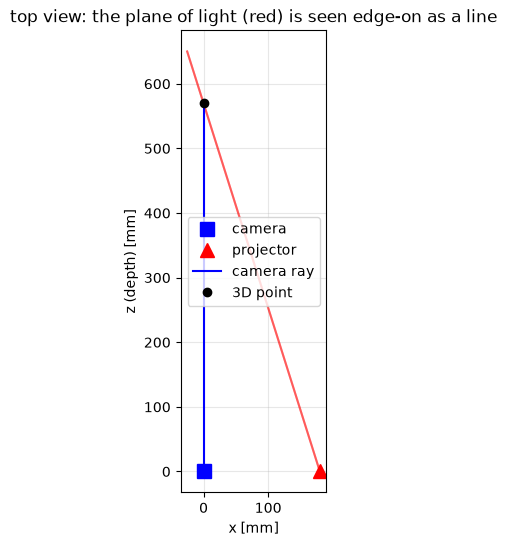

In [5]:
def rotation_y(degrees):
    a = np.radians(degrees)
    return np.array([[np.cos(a), 0, np.sin(a)], [0, 1, 0], [-np.sin(a), 0, np.cos(a)]])

W_CAM, H_CAM = 320, 240
K_cam = np.array([[800.0, 0, 160], [0, 800.0, 120], [0, 0, 1]])
camera = [K_cam, np.zeros(5), np.eye(3), np.zeros((3, 1))]        # world frame = camera frame

W_PROJ, H_PROJ = 640, 400
K_proj = np.array([[900.0, 0, 320], [0, 900.0, 200], [0, 0, 1]])
R_proj = rotation_y(17.5)                                          # turned toward the scene
C_proj = np.array([180.0, 0.0, 0.0])                               # baseline b = 180 mm
projector = [K_proj, np.zeros(5), R_proj, (-R_proj @ C_proj).reshape(3, 1)]

# one edge at panel column 320 -> its plane of light
edge_ends = np.array([[319.5, -0.5], [319.5, H_PROJ - 0.5]])
Cp, dp = pixel_to_ray(*projector, edge_ends)
normal = np.cross(dp[0], dp[1])
print('projector centre', Cp, ' plane normal', (normal / np.linalg.norm(normal)).round(3))

# one camera pixel -> its ray -> intersection with the plane
Cc, dc = pixel_to_ray(*camera, np.array([[160.0, 120.0]]))
P = intersect(Cc, dc, Cp, normal)[0]
print('camera pixel (160, 120) sees the plane of light at', P.round(1), 'mm')

# picture of the geometry, seen from above (x-z plane)
fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(*Cc[[0, 2]], 'bs', ms=10, label='camera'); ax.plot(*Cp[[0, 2]], 'r^', ms=10, label='projector')
for d in dp:
    ax.plot([Cp[0], Cp[0] + 650 * d[0] / d[2]], [Cp[2], 650], 'r-', alpha=0.4)
ax.plot([0, P[0]], [0, P[2]], 'b-', label='camera ray'); ax.plot(P[0], P[2], 'ko', label='3D point')
ax.set_xlabel('x [mm]'); ax.set_ylabel('z (depth) [mm]'); ax.set_aspect('equal'); ax.legend(); ax.grid(alpha=0.3)
ax.set_title('top view: the plane of light (red) is seen edge-on as a line')
plt.show()

## 5. A complete mini-scan with a known answer

To check the whole pipeline, we "photograph" a synthetic object whose true shape we know: a tilted plane with a round bump 40 mm high. For every camera pixel we compute the 3D surface point, look up whether the projector lights it (it is lit if it falls right of the edge on the panel), and add a striped surface texture and some camera noise. Then we run **the solution's** `detect_edge` and `reconstruct` and compare the result with the true surface.

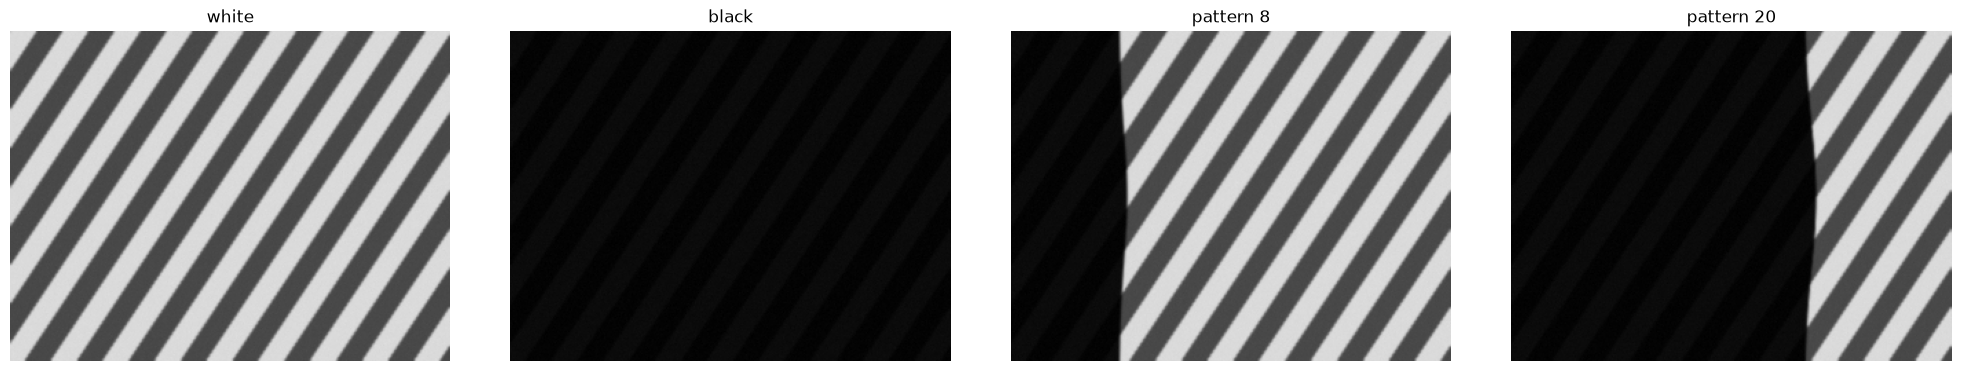

In [6]:
def true_depth(x, y):
    """Surface: tilted plane at about 570 mm with a bump 40 mm toward the camera"""
    return 570 + 0.2 * x - 40 * np.exp(-(x ** 2 + y ** 2) / (2 * 35 ** 2))

# 3D point seen by every camera pixel (fixed-point iteration along each ray)
u, v = np.meshgrid(np.arange(W_CAM, dtype=float), np.arange(H_CAM, dtype=float))
rays = np.linalg.inv(K_cam) @ np.stack([u.ravel(), v.ravel(), np.ones(u.size)])
z = np.full(u.size, 570.0)
for _ in range(30):
    z = true_depth(rays[0] * z, rays[1] * z)
surface = (rays * z).T                                           # (N, 3) true 3D points

# where each surface point falls on the projector panel
p = (K_proj @ (R_proj @ (surface - C_proj).T)).T
panel_x = (p[:, 0] / p[:, 2]).reshape(H_CAM, W_CAM)
inside = ((p[:, 1] / p[:, 2] >= 0) & (p[:, 1] / p[:, 2] < H_PROJ)).reshape(H_CAM, W_CAM)

rng = np.random.default_rng(0)
texture = 0.6 + 0.3 * np.sign(np.sin(u / 6 + v / 9))               # striped surface
def photograph(light):
    image = texture * (0.05 + 0.9 * light * inside)
    image = cv.GaussianBlur(image, (0, 0), 0.8)
    return image + rng.normal(0, 0.005, image.shape)

columns = np.linspace(150, 500, 30).round()
scan = [photograph(np.clip(panel_x - (c - 0.5) + 0.5, 0, 1)) for c in columns]   # dark left, light right
white, black = photograph(np.ones_like(panel_x)), photograph(np.zeros_like(panel_x))
synthetic_panel = np.stack([np.column_stack([columns - 0.5, np.full(len(columns), -0.5)]),
                            np.column_stack([columns - 0.5, np.full(len(columns), H_PROJ - 0.5)])])

fig, axes = plt.subplots(1, 4, figsize=(20, 3.6), constrained_layout=True)
for ax, (title, image) in zip(axes, [('white', white), ('black', black), ('pattern 8', scan[7]), ('pattern 20', scan[19])]):
    ax.imshow(image, cmap='gray', vmin=0, vmax=1); ax.set_title(title); ax.axis('off')
plt.show()

detect_edge: only 0 points found (at least 20 wanted)
6960 points from 30 patterns; depth error: mean +0.010 mm, RMS 0.265 mm


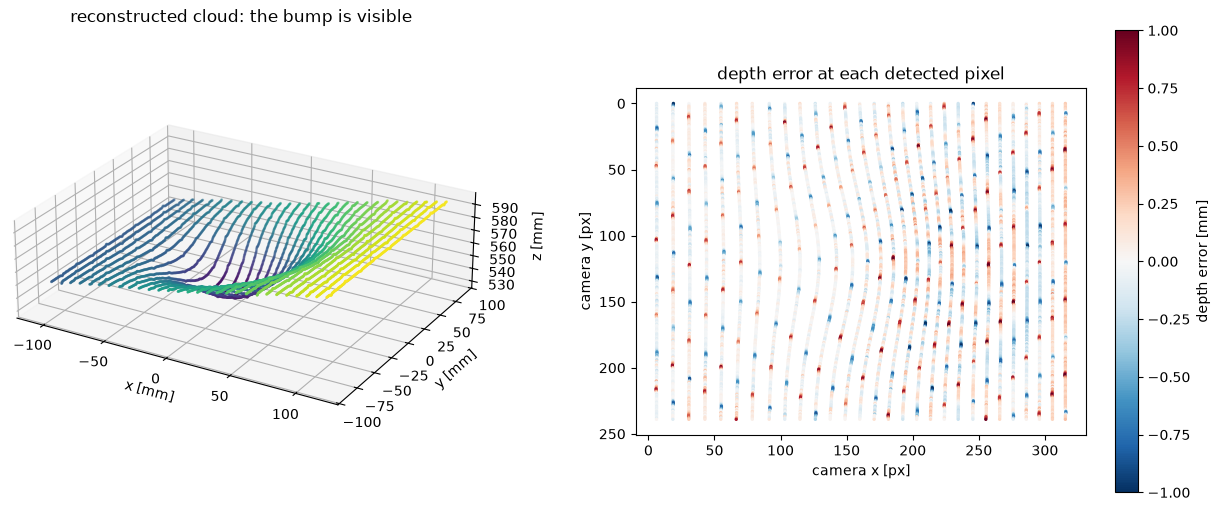

In [7]:
sensor_points = [detect_edge(image, white, black) for image in scan]
cloud = reconstruct(sensor_points, synthetic_panel, camera, projector)

# compare with the truth: true depth at the same camera pixels
all_pixels = np.concatenate(sensor_points)
true = np.array([true_depth(*(np.linalg.inv(K_cam) @ [x, y, 1])[:2] * zz) for (x, y), zz in
                 zip(all_pixels, cloud[:, 2])])
error = cloud[:, 2] - true
print(f'{len(cloud)} points from {len(scan)} patterns; depth error: mean {error.mean():+.3f} mm, RMS {np.sqrt(np.mean(error ** 2)):.3f} mm')

fig = plt.figure(figsize=(16, 6))
ax = fig.add_subplot(1, 2, 1, projection='3d')
ax.scatter(cloud[:, 0], cloud[:, 1], cloud[:, 2], c=cloud[:, 2], s=1, cmap='viridis')
ax.set_box_aspect(np.ptp(cloud, axis=0)); ax.view_init(25, -60)
ax.set_xlabel('x [mm]'); ax.set_ylabel('y [mm]'); ax.set_zlabel('z [mm]'); ax.set_title('reconstructed cloud: the bump is visible')
ax = fig.add_subplot(1, 2, 2)
sc = ax.scatter(all_pixels[:, 0], all_pixels[:, 1], c=error, s=2, cmap='RdBu_r', vmin=-1, vmax=1)
ax.invert_yaxis(); ax.set_aspect('equal'); plt.colorbar(sc, ax=ax, label='depth error [mm]')
ax.set_title('depth error at each detected pixel'); ax.set_xlabel('camera x [px]'); ax.set_ylabel('camera y [px]')
plt.show()

**What to notice:**

- The cloud is a set of **curves**, one per pattern: each pattern gives the profile of the object along one plane of light.
- The error is a small fraction of a millimetre although the surface is striped and noisy: the normalization by white − black removes the stripes, and the sub-pixel interpolation gives the precision.
- The largest errors (dark red and blue spots) sit exactly where a **stripe boundary crosses the edge**: there the camera blur mixes a dark and a bright stripe and shifts the detected edge a little. Your real flat board shows the same effect along its printed checkerboard.
- One pattern prints "only 0 points found": its edge falls outside the camera's view. That is expected and simply adds no points.
- Try it: change `columns` (more patterns → denser cloud), the noise `0.005`, or `R_proj` and `C_proj`, and run the two cells again.

## 6. The pre-lab formula $\delta z \approx \dfrac{z^2}{f\,b}\,\delta x$, tested

If the edge position in the photo is wrong by $\delta x$ pixels, the depth is wrong by about $z^2\,\delta x / (f\,b)$. We test this with the synthetic setup: take the detected edge points, shift them by random errors of standard deviation $\delta x$, reconstruct again and measure the depth error.

In [8]:
f_px, b_mm, z_mm = K_cam[0, 0], 180.0, 570.0
rows = []
for dx in (0.25, 0.5, 1.0, 2.0):
    noisy = [pts + np.column_stack([rng.normal(0, dx, len(pts)), np.zeros(len(pts))]) for pts in sensor_points]
    dz = reconstruct(noisy, synthetic_panel, camera, projector)[:, 2] - cloud[:, 2]
    rows.append((dx, np.sqrt(np.mean(dz ** 2)), z_mm ** 2 * dx / (f_px * b_mm)))
print(' delta x [px] | measured delta z [mm] | formula z^2 dx / (f b) [mm]')
for dx, measured, predicted in rows:
    print(f'   {dx:5.2f}      |        {measured:6.3f}         |        {predicted:6.3f}')

 delta x [px] | measured delta z [mm] | formula z^2 dx / (f b) [mm]
    0.25      |         0.556         |         0.564
    0.50      |         1.119         |         1.128
    1.00      |         2.222         |         2.256
    2.00      |         4.383         |         4.513


**What to notice:** the error grows **linearly** with $\delta x$ and the formula predicts its size well (it is a simplified 2D model, so the match is close, not exact). The same formula tells how to reduce the noise: a longer baseline $b$, a longer focal length $f$ or a shorter distance $z$.

## 7. `fit_plane`: how flat is a flat board?

`fit_plane` finds the best plane through a cloud with the SVD: after subtracting the mean, the direction in which the points spread **least** is the plane's normal. The RMS distance of the points from the plane is the depth noise measured in the analysis.

**Example:** a plane with 0.3 mm of noise, once flat and once slightly bent.

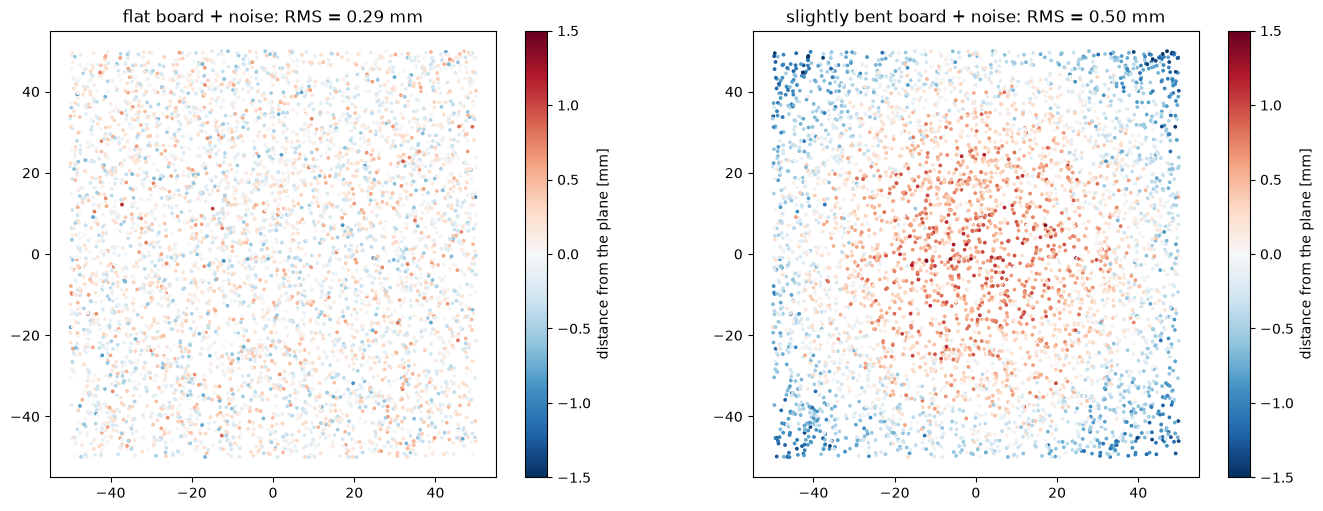

In [ ]:
xy = rng.uniform(-50, 50, size=(5000, 2))
flat = np.column_stack([xy, 600 + 0.3 * xy[:, 0] + rng.normal(0, 0.3, 5000)])
bent = flat + np.column_stack([np.zeros((5000, 2)), 0.0004 * (xy ** 2).sum(axis=1)])   # bowl, 2 mm at the corners

fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
for ax, (name, pts) in zip(axes, [('flat board + noise', flat), ('slightly bent board + noise', bent)]):
    point, normal, rms = fit_plane(pts)
    residual = (pts - point) @ normal
    sc = ax.scatter(xy[:, 0], xy[:, 1], c=residual, s=3, cmap='RdBu_r', vmin=-1.5, vmax=1.5)
    ax.set_aspect('equal'); ax.set_title(f'{name}: RMS = {rms:.2f} mm')
    plt.colorbar(sc, ax=ax, label='distance from the plane [mm]')
plt.show()

**What to notice:** random noise gives a speckled map with RMS ≈ the noise (0.3 mm). A *systematic* error (here a bend) shows up as a **pattern** in the map and increases the RMS. In your own flat-board map, the pattern follows the printed checkerboard: the edge detection is slightly biased on black versus white squares.

## 8. Your real data: one scan photo, from pixels to 3D points

Now the same steps on one of your photos of the object. Photo $k$ was taken under pattern $k + 62$, so photo 12 belongs to the edge stored at index $12 + 62 - 1 = 73$ of the panel points. This part needs your calibration in `setup-act/calibration-data` (written by the solution notebook).

calibration found


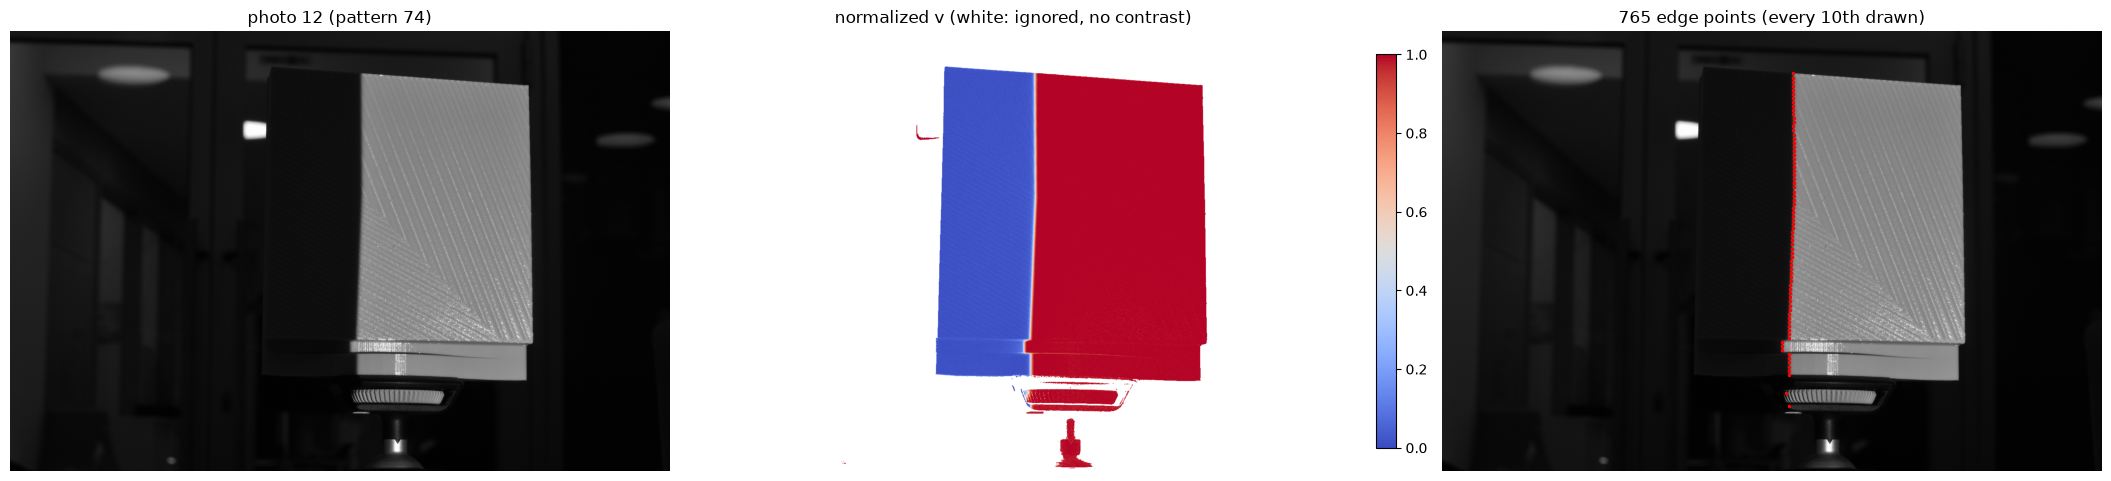

In [10]:
ACT = 'setup-act'
have_data = os.path.exists(os.path.join(ACT, 'calibration-data', 'camera-intrinsic-matrix.npy'))
print('calibration found' if have_data else 'Run L08-solution.ipynb first: no calibration in setup-act/calibration-data')

def read_gray(name):
    image = cv.cvtColor(cv.imread(name, cv.IMREAD_COLOR), cv.COLOR_BGR2RGB).astype(np.float32) / 255.0
    return to_gray(image).astype(np.float32)

if have_data:
    use_solution_code('l08-009')                                  # load_calibration
    my_camera, my_projector = load_calibration(os.path.join(ACT, 'calibration-data'))
    panel = load_projector_panel_points(os.path.join(ACT, 'panel_upper_points.npy'), os.path.join(ACT, 'panel_lower_points.npy'))
    folder = os.path.join(ACT, 'reconstruction-dataset')
    k = 12
    photo, white_photo, black_photo = (read_gray(os.path.join(folder, f'reconstruction-{tag}.JPG'))
                                       for tag in (f'{k:02d}', 'white', 'black'))
    contrast = white_photo - black_photo
    v_real = np.where(contrast > 0.08, (photo - black_photo) / np.maximum(contrast, 1e-6), np.nan)
    pts = detect_edge(photo, white_photo, black_photo)

    fig, axes = plt.subplots(1, 3, figsize=(21, 5), constrained_layout=True)
    axes[0].imshow(photo, cmap='gray'); axes[0].set_title(f'photo {k} (pattern {k + 62})')
    im = axes[1].imshow(v_real, cmap='coolwarm', vmin=0, vmax=1); fig.colorbar(im, ax=axes[1], shrink=0.8)
    axes[1].set_title('normalized v (white: ignored, no contrast)')
    axes[2].imshow(photo, cmap='gray'); axes[2].plot(pts[::10, 0], pts[::10, 1], 'r.', ms=3)
    axes[2].set_title(f'{len(pts)} edge points (every 10th drawn)')
    for ax in axes: ax.axis('off')
    plt.show()

panel ends of the edge: [[924.5, -0.5], [924.5, 799.5]]
camera centre [101.1 100.7 563. ] mm, projector centre [-76.7 138.6 541. ] mm, baseline 183.2 mm
765 3D points, distance from the camera 577…594 mm


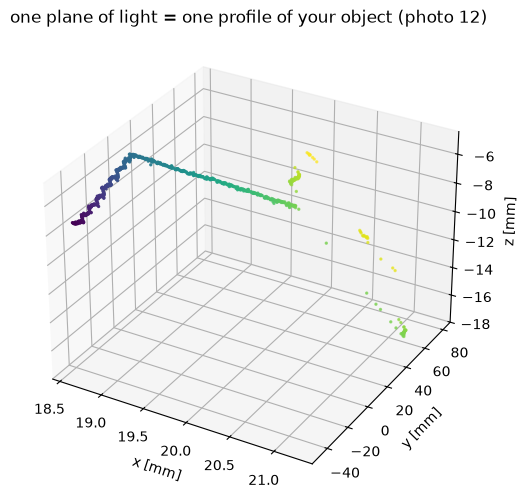

In [11]:
if have_data:
    edge = panel[:, k + 62 - 1, :]                                   # the two ends of this edge on the panel
    Cp, dp = pixel_to_ray(*my_projector, edge)
    normal = np.cross(dp[0], dp[1])
    Cc, dc = pixel_to_ray(*my_camera, pts)
    profile = intersect(Cc, dc, Cp, normal)
    print('panel ends of the edge:', edge.tolist())
    print(f'camera centre {Cc.round(1)} mm, projector centre {Cp.round(1)} mm, baseline {np.linalg.norm(Cp - Cc):.1f} mm')
    print(f'{len(profile)} 3D points, distance from the camera {np.linalg.norm(profile - Cc, axis=1).min():.0f}…'
          f'{np.linalg.norm(profile - Cc, axis=1).max():.0f} mm')

    fig = plt.figure(figsize=(8, 6))
    ax = fig.add_subplot(projection='3d')
    ax.scatter(profile[:, 0], profile[:, 1], profile[:, 2], c=profile[:, 1], s=2, cmap='viridis')
    ax.set_xlabel('x [mm]'); ax.set_ylabel('y [mm]'); ax.set_zlabel('z [mm]')
    ax.set_title(f'one plane of light = one profile of your object (photo {k})')
    plt.show()

**What to notice:** one photo gives **one curve** on the object, the profile cut by one plane of light. The flat front face appears as a straight line and the step at the bottom as a jump. Repeating this for all 35 photos gives the full point cloud of the solution.

## 9. Your real data: how the calibration finds its features

**Camera.** The checkerboard plate has a three-dot marker in its centre. OpenCV finds the inner corners and tells which corner is at the marker; that corner becomes the origin (0, 0) mm, and every other corner gets coordinates in steps of 10 mm. With 17 poses, `cv.calibrateCamera` finds the focal length, image centre and lens distortion.

**Projector.** The dot photo is divided by the white photo of the same pose. This cancels the printed squares, so only the projected dots remain. Dots are searched only where the projector actually lights the plate.

21 x 16 inner corners, marker at corner (row, column) = (5, 6)


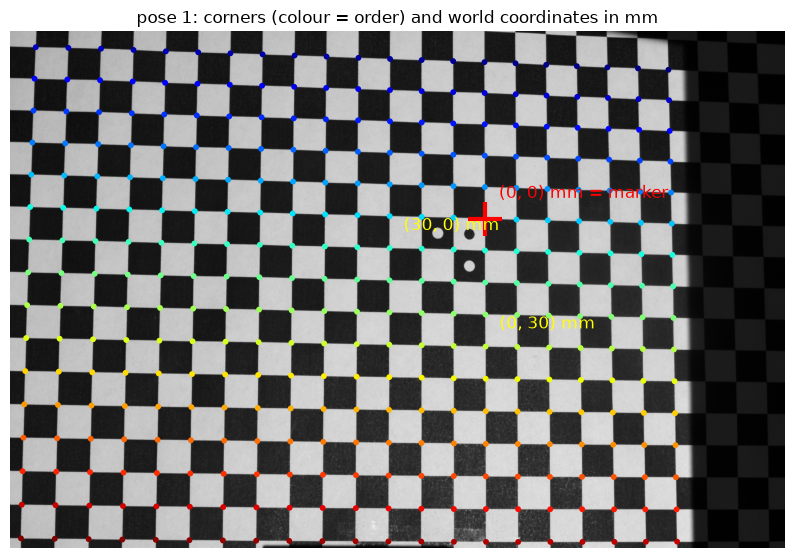

In [12]:
calib = os.path.join(ACT, 'calibration-dataset')
if os.path.exists(os.path.join(calib, 'pose-01-white.JPG')):
    use_solution_code('l08-036', stop_at='if not calib_white_files')    # detect_chessboard and its settings
    white_pose = read_gray(os.path.join(calib, 'pose-01-white.JPG'))
    corners, origin = detect_chessboard(white_pose)
    rows_, cols_ = corners.shape[:2]
    print(f'{cols_} x {rows_} inner corners, marker at corner (row, column) = {origin}')

    fig, ax = plt.subplots(figsize=(10, 7))
    ax.imshow(white_pose, cmap='gray')
    ax.scatter(corners[..., 0].ravel(), corners[..., 1].ravel(), c=np.arange(rows_ * cols_), cmap='jet', s=10)
    ax.plot(*corners[origin], 'r+', ms=25, mew=3)
    for (r_, c_) in [(origin[0], origin[1] + 3), (origin[0] + 3, origin[1])]:
        ax.annotate(f'({(c_ - origin[1]) * 10:.0f}, {(r_ - origin[0]) * 10:.0f}) mm', corners[r_, c_], color='yellow',
                    fontsize=12, xytext=(10, -10), textcoords='offset points')
    ax.annotate('(0, 0) mm = marker', corners[origin], color='red', fontsize=12, xytext=(10, 15), textcoords='offset points')
    ax.set_title('pose 1: corners (colour = order) and world coordinates in mm'); ax.axis('off')
    plt.show()

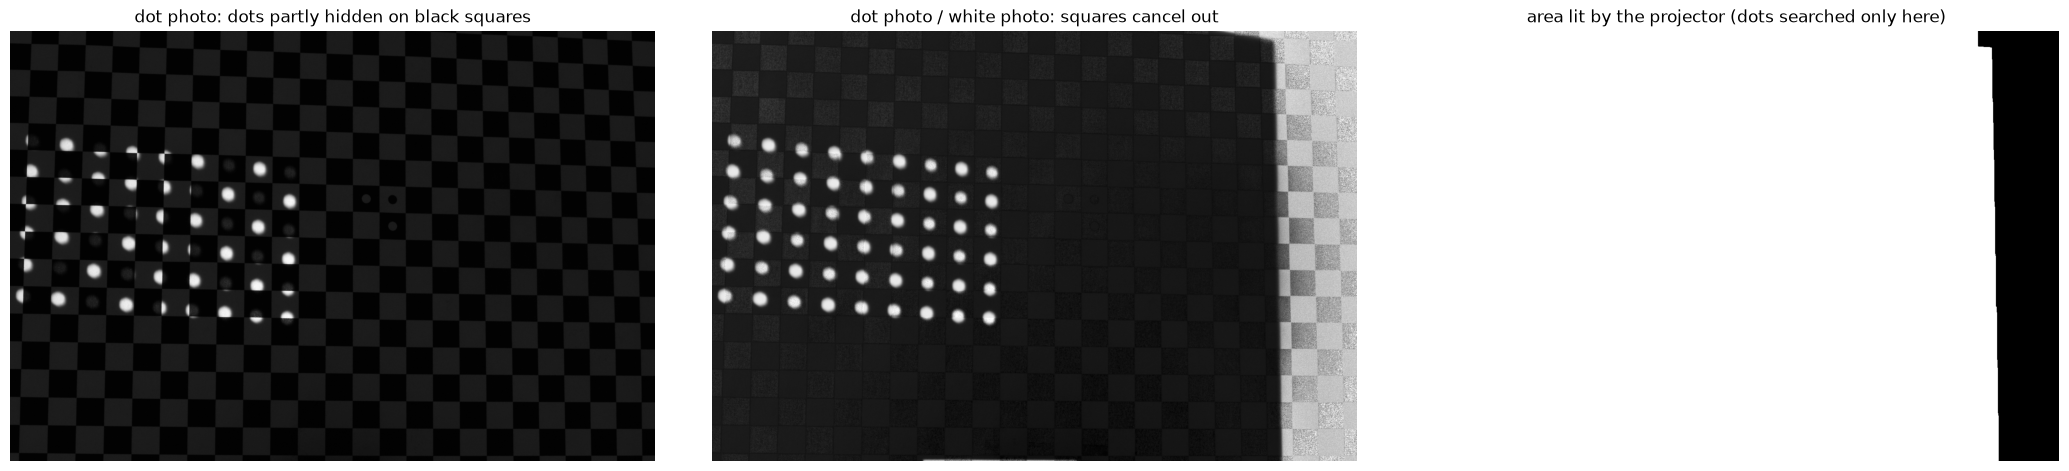

In [13]:
if os.path.exists(os.path.join(calib, 'pose-01-pattern.JPG')):
    pattern_pose = read_gray(os.path.join(calib, 'pose-01-pattern.JPG'))
    ratio = np.where(white_pose > 0.003, pattern_pose / np.maximum(white_pose, 1e-6), 0)
    k_ = int(round(white_pose.shape[1] / 20)) | 1
    level = cv.dilate(white_pose, np.ones((k_, k_), np.uint8))
    lit = level > 0.4 * np.percentile(level, 99)

    fig, axes = plt.subplots(1, 3, figsize=(21, 4.6), constrained_layout=True)
    axes[0].imshow(pattern_pose, cmap='gray'); axes[0].set_title('dot photo: dots partly hidden on black squares')
    axes[1].imshow(np.clip(ratio, 0, 1.2), cmap='gray'); axes[1].set_title('dot photo / white photo: squares cancel out')
    axes[2].imshow(lit, cmap='gray'); axes[2].set_title('area lit by the projector (dots searched only here)')
    for ax in axes: ax.axis('off')
    plt.show()

**What to notice:** after the division every dot is equally bright, whether it fell on a black or a white square. On the right side of the plate (not lit by the projector) the division only amplifies noise, so the code ignores that area.

Then, for each pose, the code knows for every dot **where it is on the panel** (from the pattern file) and **where it is in 3D** (its camera ray hits the plate, whose position is known from the camera calibration). From these pairs, `cv.calibrateCamera` calibrates the projector exactly like a camera.

---

### Summary

| Step | Function | Input → output |
|---|---|---|
| Patterns | `generate_slset` | column positions → images + edge end points |
| Edge | `detect_edge` | photo, white, black → sub-pixel edge points |
| Rays | `pixel_to_ray` | pixels + calibration → centre and directions |
| Plane | (in `reconstruct`) | two panel end points → normal $\mathbf d_1\times\mathbf d_2$ |
| 3D point | `intersect` | ray + plane → point |
| Cloud | `reconstruct` | all photos → point cloud |
| Flatness | `fit_plane` | cloud → plane + RMS |

In [14]:
# clean up the demo folder of part 2
import shutil
shutil.rmtree('_demo_patterns', ignore_errors=True)